In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

df.head()

Saving sales_data (1).csv to sales_data (1).csv


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [4]:
print("Rows and columns:", df.shape)
print(df.columns.tolist())

Rows and columns: (76000, 16)
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality', 'Epidemic', 'Demand']


In [5]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nFirst 5 rows:")
print(df.head())

Shape: (76000, 16)

Columns:
Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount',
       'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality',
       'Epidemic', 'Demand'],
      dtype='object')

First 5 rows:
         Date Store ID Product ID     Category Region  Inventory Level  \
0  2022-01-01     S001      P0001  Electronics  North              195   
1  2022-01-01     S001      P0002     Clothing  North              117   
2  2022-01-01     S001      P0003     Clothing  North              247   
3  2022-01-01     S001      P0004  Electronics  North              139   
4  2022-01-01     S001      P0005    Groceries  North              152   

   Units Sold  Units Ordered  Price  Discount Weather Condition  Promotion  \
0         102            252  72.72         5             Snowy          0   
1         117            249  80.16        15             Snowy          1   
2     

In [6]:
df["Date"] = pd.to_datetime(df["Date"])

In [7]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["DayOfWeek"] = df["Date"].dt.dayofweek

In [8]:
df["IsWeekend"] = df["DayOfWeek"].isin([5, 6]).astype(int)

In [9]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Missing values:
Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
Year                  0
Month                 0
Day                   0
DayOfWeek             0
IsWeekend             0
dtype: int64

Duplicate rows:
0

Data types:
Date                  datetime64[ns]
Store ID                      object
Product ID                    object
Category                      object
Region                        object
Inventory Level                int64
Units Sold                     int64
Units Ordered                  int64
Price                        float64
Discount                       int64
Weather Condition             object
Promotion                   

In [10]:
df.describe()

,Date,Inventory Level,Units Sold,Units Ordered,Price,Discount,Promotion,Competitor Pricing,Epidemic,Demand,Year,Month,Day,DayOfWeek,IsWeekend
count,76000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.0000,76000.000000
mean,2023-01-15 12:00:00,301.062842,88.827316,89.090645,67.726028,9.087039,0.328947,69.454029,0.200000,104.317158,2022.559211,6.307895,15.711842,3.0000,0.286842
min,2022-01-01 00:00:00,0.000000,0.000000,0.000000,4.740000,0.000000,0.000000,4.290000,0.000000,4.000000,2022.000000,1.000000,1.000000,0.0000,0.000000
25%,2022-07-09 18:00:00,136.000000,58.000000,0.000000,31.997500,5.000000,0.000000,32.620000,0.000000,71.000000,2022.000000,3.000000,8.000000,1.0000,0.000000
50%,2023-01-15 12:00:00,227.000000,84.000000,0.000000,64.500000,10.000000,0.000000,65.700000,0.000000,100.000000,2023.000000,6.000000,16.000000,3.0000,0.000000
75%,2023-07-24 06:00:00,408.000000,114.000000,121.000000,95.830000,10.000000,1.000000,97.932500,0.000000,133.000000,2023.000000,9.000000,23.000000,5.0000,1.000000
max,2024-01-30 00:00:00,2267.000000,426.000000,1616.000000,228.030000,25.000000,1.000000,261.220000,1.000000,430.000000,2024.000000,12.000000,31.000000,6.0000,1.000000
std,NaN,226.510161,43.994525,162.404627,39.377899,7.475781,0.469834,40.943818,0.400003,46.964801,0.570479,3.546325,8.790894,2.0033,0.452290


In [11]:
print(df["Category"].value_counts())
print(df["Store ID"].value_counts())
print(df["Promotion"].value_counts())
print(df["Seasonality"].value_counts())

Category
Groceries      30400
Furniture      13680
Clothing       12160
Toys           10640
Electronics     9120
Name: count, dtype: int64
Store ID
S001    15200
S002    15200
S003    15200
S004    15200
S005    15200
Name: count, dtype: int64
Promotion
0    51000
1    25000
Name: count, dtype: int64
Seasonality
Winter    21000
Spring    18400
Summer    18400
Autumn    18200
Name: count, dtype: int64


In [12]:
# Check number of rows and columns
print("Shape of dataset:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types
print("\nData types:")
print(df.dtypes)

Shape of dataset: (76000, 21)

Column names:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality', 'Epidemic', 'Demand', 'Year', 'Month', 'Day', 'DayOfWeek', 'IsWeekend']

Data types:
Date                  datetime64[ns]
Store ID                      object
Product ID                    object
Category                      object
Region                        object
Inventory Level                int64
Units Sold                     int64
Units Ordered                  int64
Price                        float64
Discount                       int64
Weather Condition             object
Promotion                      int64
Competitor Pricing           float64
Seasonality                   object
Epidemic                       int64
Demand                         int64
Year                           int32
Month                          int32
Day  

In [13]:
# Check missing values in each column
missing_values = df.isnull().sum()

print(missing_values)

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
Year                  0
Month                 0
Day                   0
DayOfWeek             0
IsWeekend             0
dtype: int64


In [14]:
# Count duplicate rows
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [15]:
# Convert Date column to datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Check the result
print(df["Date"].dtype)

datetime64[ns]


In [16]:
# Statistical summary of numerical columns
df.describe()

,Date,Inventory Level,Units Sold,Units Ordered,Price,Discount,Promotion,Competitor Pricing,Epidemic,Demand,Year,Month,Day,DayOfWeek,IsWeekend
count,76000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.0000,76000.000000
mean,2023-01-15 12:00:00,301.062842,88.827316,89.090645,67.726028,9.087039,0.328947,69.454029,0.200000,104.317158,2022.559211,6.307895,15.711842,3.0000,0.286842
min,2022-01-01 00:00:00,0.000000,0.000000,0.000000,4.740000,0.000000,0.000000,4.290000,0.000000,4.000000,2022.000000,1.000000,1.000000,0.0000,0.000000
25%,2022-07-09 18:00:00,136.000000,58.000000,0.000000,31.997500,5.000000,0.000000,32.620000,0.000000,71.000000,2022.000000,3.000000,8.000000,1.0000,0.000000
50%,2023-01-15 12:00:00,227.000000,84.000000,0.000000,64.500000,10.000000,0.000000,65.700000,0.000000,100.000000,2023.000000,6.000000,16.000000,3.0000,0.000000
75%,2023-07-24 06:00:00,408.000000,114.000000,121.000000,95.830000,10.000000,1.000000,97.932500,0.000000,133.000000,2023.000000,9.000000,23.000000,5.0000,1.000000
max,2024-01-30 00:00:00,2267.000000,426.000000,1616.000000,228.030000,25.000000,1.000000,261.220000,1.000000,430.000000,2024.000000,12.000000,31.000000,6.0000,1.000000
std,NaN,226.510161,43.994525,162.404627,39.377899,7.475781,0.469834,40.943818,0.400003,46.964801,0.570479,3.546325,8.790894,2.0033,0.452290


In [17]:
print("Categories:")
print(df["Category"].unique())

print("\nStores:")
print(df["Store ID"].unique())

print("\nRegions:")
print(df["Region"].unique())

print("\nPromotion values:")
print(df["Promotion"].unique())

print("\nSeasonality:")
print(df["Seasonality"].unique())

Categories:
['Electronics' 'Clothing' 'Groceries' 'Toys' 'Furniture']

Stores:
['S001' 'S002' 'S003' 'S004' 'S005']

Regions:
['North' 'South' 'East' 'West']

Promotion values:
[0 1]

Seasonality:
['Winter' 'Spring' 'Summer' 'Autumn']


In [18]:
# Extract useful information from Date
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["DayOfWeek"] = df["Date"].dt.dayofweek

# Weekend indicator
df["IsWeekend"] = df["DayOfWeek"].isin([5, 6]).astype(int)

In [19]:
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,...,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand,Year,Month,Day,DayOfWeek,IsWeekend
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,...,0,85.73,Winter,0,115,2022,1,1,5,1
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,...,1,92.02,Winter,0,229,2022,1,1,5,1
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,...,1,60.08,Winter,0,157,2022,1,1,5,1
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,...,0,85.19,Winter,0,52,2022,1,1,5,1
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,...,0,51.63,Winter,0,59,2022,1,1,5,1


In [20]:
print(df.shape)
print(df.isnull().sum())
print(df.describe())

(76000, 21)
Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
Year                  0
Month                 0
Day                   0
DayOfWeek             0
IsWeekend             0
dtype: int64
                      Date  Inventory Level    Units Sold  Units Ordered  \
count                76000     76000.000000  76000.000000   76000.000000   
mean   2023-01-15 12:00:00       301.062842     88.827316      89.090645   
min    2022-01-01 00:00:00         0.000000      0.000000       0.000000   
25%    2022-07-09 18:00:00       136.000000     58.000000       0.000000   
50%    2023-01-15 12:00:00       227.000000     84.000000       0.000000   
75%    2023-07-

In [21]:
# Overall business statistics

print("Total Stores:", df["Store ID"].nunique())
print("Total Products:", df["Product ID"].nunique())
print("Total Categories:", df["Category"].nunique())

print("\nTotal Units Sold:", df["Units Sold"].sum())
print("Total Units Ordered:", df["Units Ordered"].sum())

print("\nAverage Daily Units Sold:", df["Units Sold"].mean())
print("Average Inventory Level:", df["Inventory Level"].mean())
print("Average Demand:", df["Demand"].mean())

Total Stores: 5
Total Products: 20
Total Categories: 5

Total Units Sold: 6750876
Total Units Ordered: 6770889

Average Daily Units Sold: 88.82731578947369
Average Inventory Level: 301.06284210526314
Average Demand: 104.31715789473684


In [22]:
category_sales = (
    df.groupby("Category")["Units Sold"]
      .sum()
      .sort_values(ascending=False)
)

print(category_sales)

Category
Groceries      3127335
Clothing       1150873
Furniture       880654
Toys            834679
Electronics     757335
Name: Units Sold, dtype: int64


In [23]:
category_avg = (
    df.groupby("Category")["Units Sold"]
      .mean()
      .sort_values(ascending=False)
)

print(category_avg)

Category
Groceries      102.872862
Clothing        94.644161
Electronics     83.041118
Toys            78.447274
Furniture       64.375292
Name: Units Sold, dtype: float64


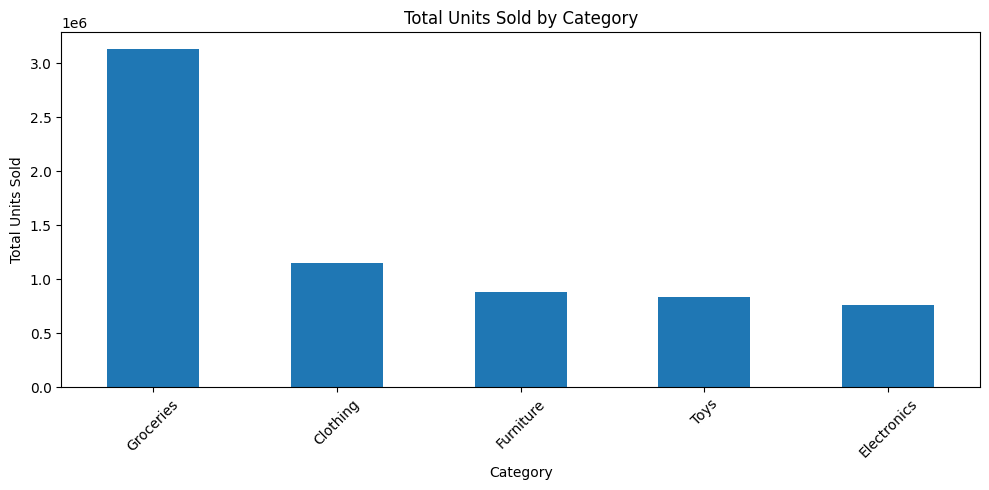

In [24]:
plt.figure(figsize=(10, 5))

category_sales.plot(kind="bar")

plt.title("Total Units Sold by Category")
plt.xlabel("Category")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
product_sales = (
    df.groupby("Product ID")["Units Sold"]
      .sum()
      .sort_values(ascending=False)
)

print(product_sales)

Product ID
P0007    379709
P0004    377627
P0009    376771
P0013    376717
P0002    359355
P0010    357299
P0001    356814
P0005    351765
P0006    344589
P0003    341531
P0015    335443
P0011    332883
P0016    326718
P0008    323317
P0014    317397
P0019    313209
P0018    310597
P0012    296256
P0017    294918
P0020    277961
Name: Units Sold, dtype: int64


In [26]:
print("Top 10 Fast-Moving Products:")
print(product_sales.head(10))

Top 10 Fast-Moving Products:
Product ID
P0007    379709
P0004    377627
P0009    376771
P0013    376717
P0002    359355
P0010    357299
P0001    356814
P0005    351765
P0006    344589
P0003    341531
Name: Units Sold, dtype: int64


In [27]:
print("\nBottom 10 Slow-Moving Products:")
print(product_sales.tail(10))


Bottom 10 Slow-Moving Products:
Product ID
P0015    335443
P0011    332883
P0016    326718
P0008    323317
P0014    317397
P0019    313209
P0018    310597
P0012    296256
P0017    294918
P0020    277961
Name: Units Sold, dtype: int64


In [28]:
product_avg_sales = (
    df.groupby("Product ID")["Units Sold"]
      .mean()
      .sort_values(ascending=False)
)

print("Top 10 Products by Average Daily Sales:")
print(product_avg_sales.head(10))

Top 10 Products by Average Daily Sales:
Product ID
P0007    99.923421
P0004    99.375526
P0009    99.150263
P0013    99.136053
P0002    94.567105
P0010    94.026053
P0001    93.898421
P0005    92.569737
P0006    90.681316
P0003    89.876579
Name: Units Sold, dtype: float64


In [29]:
print("\nBottom 10 Products by Average Daily Sales:")
print(product_avg_sales.tail(10))


Bottom 10 Products by Average Daily Sales:
Product ID
P0015    88.274474
P0011    87.600789
P0016    85.978421
P0008    85.083421
P0014    83.525526
P0019    82.423421
P0018    81.736053
P0012    77.962105
P0017    77.610000
P0020    73.147632
Name: Units Sold, dtype: float64


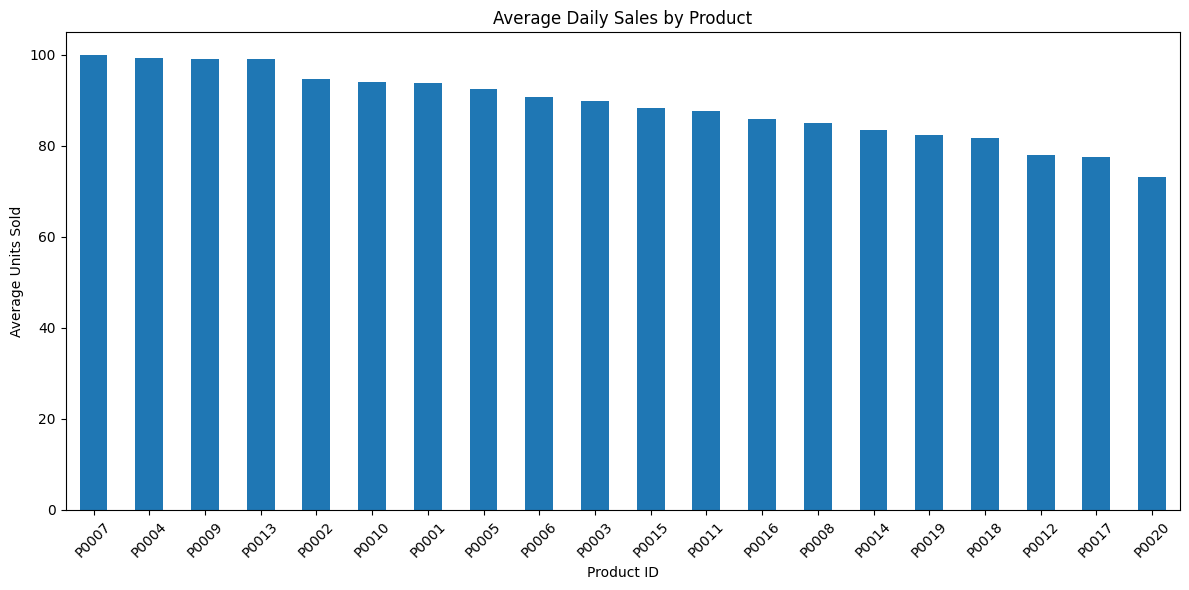

In [30]:
plt.figure(figsize=(12, 6))

product_avg_sales.sort_values(ascending=False).plot(kind="bar")

plt.title("Average Daily Sales by Product")
plt.xlabel("Product ID")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
inventory_by_product = (
    df.groupby("Product ID")["Inventory Level"]
      .mean()
      .sort_values(ascending=False)
)

print("Average Inventory by Product:")
print(inventory_by_product)

Average Inventory by Product:
Product ID
P0007    466.860000
P0005    392.904211
P0013    382.652632
P0011    345.631053
P0015    340.976316
P0014    339.902895
P0001    331.758684
P0004    320.350000
P0010    310.549474
P0003    310.263684
P0016    289.913684
P0012    289.895789
P0002    285.830789
P0020    283.483158
P0006    283.058421
P0009    272.303684
P0017    225.173684
P0019    212.485526
P0018    185.831842
P0008    151.431316
Name: Inventory Level, dtype: float64


In [32]:
product_summary = df.groupby("Product ID").agg(
    Average_Sales=("Units Sold", "mean"),
    Total_Sales=("Units Sold", "sum"),
    Average_Inventory=("Inventory Level", "mean"),
    Average_Demand=("Demand", "mean"),
    Average_Orders=("Units Ordered", "mean")
)

product_summary = product_summary.sort_values(
    "Average_Sales",
    ascending=False
)

print(product_summary)

            Average_Sales  Total_Sales  Average_Inventory  Average_Demand  \
Product ID                                                                  
P0007           99.923421       379709         466.860000      115.023421   
P0004           99.375526       377627         320.350000      115.396053   
P0009           99.150263       376771         272.303684      118.506316   
P0013           99.136053       376717         382.652632      116.025000   
P0002           94.567105       359355         285.830789      112.066579   
P0010           94.026053       357299         310.549474      111.069474   
P0001           93.898421       356814         331.758684      109.591316   
P0005           92.569737       351765         392.904211      107.520526   
P0006           90.681316       344589         283.058421      107.722368   
P0003           89.876579       341531         310.263684      103.995263   
P0015           88.274474       335443         340.976316      102.491579   

In [33]:
zero_inventory = (df["Inventory Level"] == 0).sum()

print("Zero inventory records:", zero_inventory)
print("Zero inventory percentage:",
      zero_inventory / len(df) * 100)

Zero inventory records: 406
Zero inventory percentage: 0.5342105263157895


In [34]:
low_stock_threshold = df["Inventory Level"].quantile(0.10)

print("Low-stock threshold:", low_stock_threshold)

Low-stock threshold: 95.0


In [35]:
df["Low_Stock"] = (
    df["Inventory Level"] <= low_stock_threshold
).astype(int)

print(df["Low_Stock"].value_counts())

Low_Stock
0    68184
1     7816
Name: count, dtype: int64


In [36]:
promotion_sales = (
    df.groupby("Promotion")["Units Sold"]
      .mean()
)

print(promotion_sales)

Promotion
0     81.833314
1    103.095080
Name: Units Sold, dtype: float64


In [37]:
promotion_demand = (
    df.groupby("Promotion")["Demand"]
      .mean()
)

print("\nAverage Demand:")
print(promotion_demand)


Average Demand:
Promotion
0     95.026843
1    123.269400
Name: Demand, dtype: float64


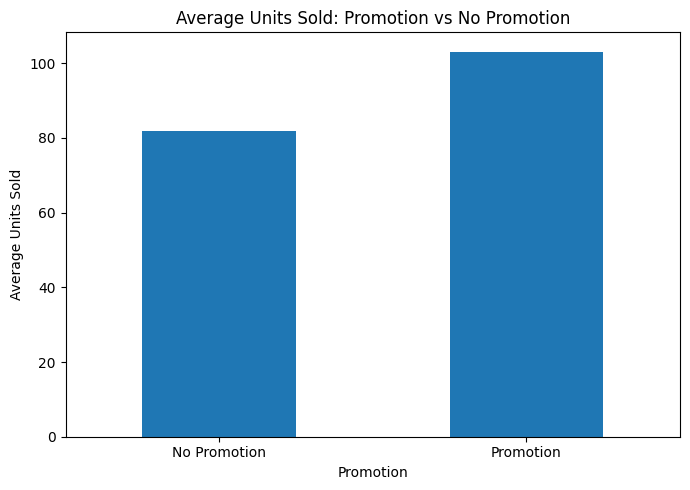

In [38]:
plt.figure(figsize=(7, 5))

promotion_sales.plot(kind="bar")

plt.title("Average Units Sold: Promotion vs No Promotion")
plt.xlabel("Promotion")
plt.ylabel("Average Units Sold")
plt.xticks([0, 1], ["No Promotion", "Promotion"], rotation=0)
plt.tight_layout()
plt.show()

In [39]:
store_summary = df.groupby("Store ID").agg(
    Average_Sales=("Units Sold", "mean"),
    Total_Sales=("Units Sold", "sum"),
    Average_Inventory=("Inventory Level", "mean"),
    Average_Demand=("Demand", "mean"),
    Average_Orders=("Units Ordered", "mean")
)

print(store_summary)

          Average_Sales  Total_Sales  Average_Inventory  Average_Demand  \
Store ID                                                                  
S001          86.719342      1318134         277.657368      101.814013   
S002          91.192500      1386126         332.014737      106.938882   
S003          90.500855      1375613         321.993026      106.468684   
S004          86.065197      1308191         293.244211      100.634934   
S005          89.658684      1362812         280.404868      105.729276   

          Average_Orders  
Store ID                  
S001           86.960461  
S002           91.530855  
S003           90.786447  
S004           86.321776  
S005           89.853684  


In [40]:
store_sales = (
    df.groupby("Store ID")["Units Sold"]
      .sum()
      .sort_values(ascending=False)
)

print(store_sales)

Store ID
S002    1386126
S003    1375613
S005    1362812
S001    1318134
S004    1308191
Name: Units Sold, dtype: int64


In [41]:
store_category_sales = pd.pivot_table(
    df,
    values="Units Sold",
    index="Store ID",
    columns="Category",
    aggfunc="mean"
)

print(store_category_sales)

Category    Clothing  Electronics  Furniture   Groceries       Toys
Store ID                                                           
S001      104.358772    78.061842  65.072368  103.980263  75.738487
S002       90.310526    82.933772  64.242105  101.982401  81.131579
S003       94.632895    91.562719  64.637719  101.729678  78.860965
S004       93.374737    74.600000  63.862970  104.684211        NaN
S005       93.538158    82.109211  64.423246  102.681711  78.832566


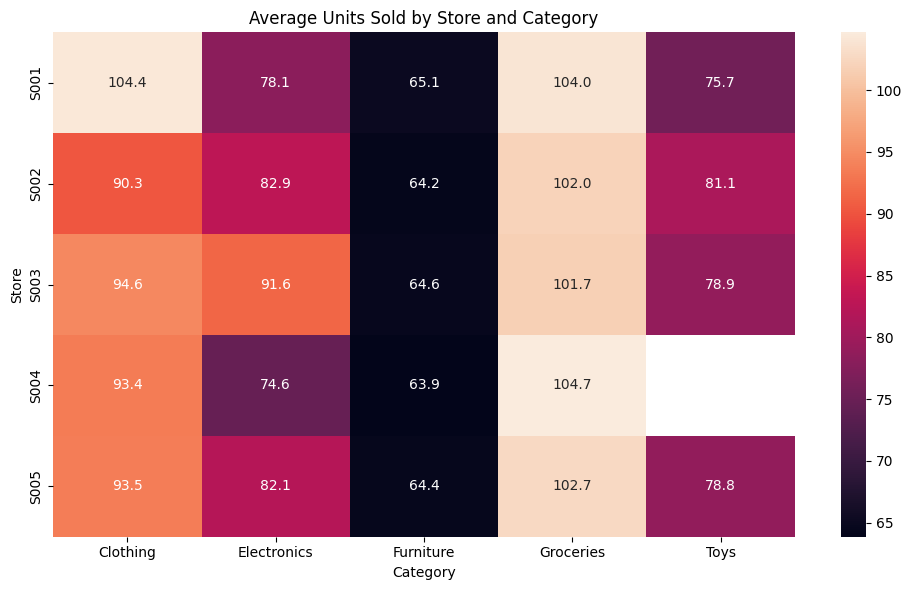

In [42]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    store_category_sales,
    annot=True,
    fmt=".1f"
)

plt.title("Average Units Sold by Store and Category")
plt.xlabel("Category")
plt.ylabel("Store")

plt.tight_layout()
plt.show()

In [43]:
print(category_sales)
print(product_avg_sales)
print(promotion_sales)
print(store_summary)

Category
Groceries      3127335
Clothing       1150873
Furniture       880654
Toys            834679
Electronics     757335
Name: Units Sold, dtype: int64
Product ID
P0007    99.923421
P0004    99.375526
P0009    99.150263
P0013    99.136053
P0002    94.567105
P0010    94.026053
P0001    93.898421
P0005    92.569737
P0006    90.681316
P0003    89.876579
P0015    88.274474
P0011    87.600789
P0016    85.978421
P0008    85.083421
P0014    83.525526
P0019    82.423421
P0018    81.736053
P0012    77.962105
P0017    77.610000
P0020    73.147632
Name: Units Sold, dtype: float64
Promotion
0     81.833314
1    103.095080
Name: Units Sold, dtype: float64
          Average_Sales  Total_Sales  Average_Inventory  Average_Demand  \
Store ID                                                                  
S001          86.719342      1318134         277.657368      101.814013   
S002          91.192500      1386126         332.014737      106.938882   
S003          90.500855      1375613         3